# 05 · Previsões com o modelo vigente e teste integrado do ciclo

Passo **10 do fluxo único**. O modelo vigente é carregado **junto com o pré-processamento e o conjunto de features** correspondentes (é um único pipeline serializado, com hash conferido contra o manifesto) e gera previsões para registros **não utilizados na escolha do modelo**: o conjunto de **teste** reservado (avaliação final) e URLs de exemplo.

Depois, verificações automáticas confirmam que neste ciclo a votação foi refeita, os dois algoritmos foram treinados e o vigente foi promovido ou mantido automaticamente; e comparamos os ciclos executados até agora.

In [1]:
import sys
from pathlib import Path

# Caminhos consistentes: localiza a raiz do projeto (pasta com config/config.yaml)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(RAIZ))
from src.config import preparar_notebook

cfg = preparar_notebook()  # muda o diretório de trabalho para a raiz do projeto

import json

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (9, 4)})

from src import ciclo, ingestao, modelagem, promocao, rastreamento, relatorio
from src import preprocessamento as pp
from src.config import ler_json, salvar_json

ctx = ciclo.carregar_ciclo(exigir=["01_etl", "02_votacao", "03_treino", "04_promocao"])
EVID = ciclo.dir_evidencias(ctx)
classes = cfg["dados"]["classes"]
manifesto, vigente = promocao.carregar_vigente()
assert vigente is not None, "não há modelo vigente aprovado para gerar previsões"
v = manifesto["vigente"]
print(f"cycle_id = {ctx['cycle_id']} | vigente = {v['versao']} ({v['algoritmo']}, promovido no ciclo {v['cycle_id']}, data_version {v['data_version']})")
print(vigente)

cycle_id = c0005-20261123T211722Z | vigente = v0002 (xgboost, promovido no ciclo c0002-20261120T174720Z, data_version dv002-ef484fad)
ModeloURL(xgboost, versao=v0002, cycle_id=c0002-20261120T174720Z, features=30)


## Previsões no conjunto de teste reservado (avaliação final)

In [2]:
base = pd.read_parquet(Path(cfg["dados"]["dir_processed"]) / "base_features.parquet")
teste = base[base["particao"] == "teste"].reset_index(drop=True)
proba = vigente.prever_proba(teste["url"])                    # a partir da URL crua: extração + pré-processamento + features
y_teste = modelagem.codificar_alvo(teste["type"], classes)
m_teste = modelagem.calcular_metricas(y_teste, proba.to_numpy(), classes)
display(pd.Series(m_teste, name="teste").round(4).to_frame().T)
display(modelagem.matriz_confusao(y_teste, proba.to_numpy(), classes))

previsoes = pd.DataFrame({"url": teste["url"], "real": teste["type"], "previsto": proba.idxmax(axis=1),
                          "confianca": proba.max(axis=1).round(4)}).join(proba.round(4).add_prefix("p_"))
previsoes.to_csv(EVID / "previsoes_teste.csv.gz", index=False, compression="gzip")
previsoes.head(300).to_csv(EVID / "previsoes_teste_amostra.csv", index=False)
display(previsoes.head(10))

,f1_macro,accuracy,balanced_accuracy,precision_macro,recall_macro,log_loss,f1_benign,recall_benign,f1_defacement,recall_defacement,f1_phishing,recall_phishing,f1_malware,recall_malware
teste,0.7676,0.7692,0.8003,0.7548,0.8003,0.5118,0.8252,0.759,0.8072,0.8571,0.5314,0.6929,0.9065,0.8921


,prev_benign,prev_defacement,prev_phishing,prev_malware
real_benign,3769,248,932,17
real_defacement,94,942,62,1
real_phishing,290,43,765,6
real_malware,16,2,16,281


,url,real,previsto,confianca,p_benign,p_defacement,p_phishing,p_malware
0,en.wikipedia.org/wiki/Somalia_Affair,benign,benign,0.7575,0.7575,0.0247,0.2164,0.0014
1,http://users2.jabry.com/kamale/Please-Update-Y...,phishing,benign,0.9767,0.9767,0.0096,0.0109,0.0029
2,cornerstonepromotion.com/theplayer/038/,benign,phishing,0.6843,0.2607,0.0530,0.6843,0.0020
3,http://www.sneakpeek3d4d.com/component/content...,defacement,defacement,0.8545,0.1282,0.8545,0.0033,0.0140
4,http://www.naylorantiques.com/mljuo/2/,phishing,phishing,0.6779,0.2536,0.0232,0.6779,0.0454
5,http://cheezburger.com/8491894272/star-wars-me...,benign,benign,0.9833,0.9833,0.0067,0.0069,0.0032
6,amuniversal.com/ups/international_division.htm,benign,benign,0.6090,0.6090,0.0553,0.3336,0.0021
7,peeperstv.com/celebs/1657/eveplumb,benign,benign,0.6985,0.6985,0.0081,0.2924,0.0010
8,http://udn.com/news/story/7088/883900-Google%E...,benign,benign,0.9992,0.9992,0.0002,0.0002,0.0004
9,http://www.gerridavis.com/galleries/172-galler...,defacement,benign,0.8556,0.8556,0.0898,0.0535,0.0012


## Previsões para URLs novas (uso do modelo)

URLs fora da base. Atenção: o modelo vê só o texto da URL; domínios curtos sem caminho (como `google.com`) são justamente a região em que benign e phishing mais se sobrepõem nesta base, então podem ser classificados de forma errada — limitação discutida no relatório.

In [3]:
exemplos = ["github.com/pedrosantos2/n3_cybersecurity", "https://www.google.com", "http://drive-google-com.verify-session.com/5e858109c170e2415e/",
            "http://192.168.10.5:8080/bins/payload.arm7", "bit.ly/3xYz9Ab", "http://www.example.com/index.php?option=com_content&view=article&id=7"]
saida = vigente.prever_proba(exemplos).round(4)
saida.insert(0, "previsto", vigente.prever(exemplos))
saida.insert(0, "url", exemplos)
display(saida)

,url,previsto,benign,defacement,phishing,malware
0,github.com/pedrosantos2/n3_cybersecurity,benign,0.9303,0.0040,0.0654,0.0003
1,https://www.google.com,phishing,0.1780,0.0001,0.8205,0.0014
2,http://drive-google-com.verify-session.com/5e8...,phishing,0.4698,0.0008,0.5278,0.0016
3,http://192.168.10.5:8080/bins/payload.arm7,malware,0.0001,0.0001,0.0012,0.9987
4,bit.ly/3xYz9Ab,phishing,0.0987,0.0014,0.8997,0.0003
5,http://www.example.com/index.php?option=com_co...,defacement,0.0015,0.9886,0.0006,0.0093


## Teste integrado do ciclo

In [4]:
runs = rastreamento.runs_do_ciclo(cfg, ctx["cycle_id"])
etapas = runs["tags.etapa"].value_counts().to_dict()
treinos = runs[runs["tags.etapa"] == "03_treino"]
run_prom = runs[runs["tags.etapa"] == "04_promocao"]
votacao = ler_json(EVID / "votacao_features.json")

# Consistência: o modelo registrado no MLflow (alias vigente) prevê igual ao bundle versionado
nome, alias = cfg["mlflow"]["modelo_registrado"], cfg["mlflow"]["alias_vigente"]
amostra = teste.head(300)
pyfunc = mlflow.pyfunc.load_model(f"models:/{nome}@{alias}")
prev_mlflow = np.asarray(pyfunc.predict(amostra[pp.COLUNAS_FEATURES]))
prev_bundle = vigente.pipeline.predict(amostra[pp.COLUNAS_FEATURES])

verificacoes = [
    {"verificacao": "votação refeita neste ciclo", "ok": etapas.get("02_votacao", 0) == 1 and votacao["cycle_id"] == ctx["cycle_id"]},
    {"verificacao": "dois algoritmos distintos treinados neste ciclo", "ok": len(treinos) == 2 and treinos["tags.algoritmo"].nunique() == 2},
    {"verificacao": "decisão automática registrada (promover/manter)", "ok": len(run_prom) == 1 and run_prom["tags.decisao"].iloc[0] in ("promover", "manter")
                                                                            and manifesto["ultima_decisao"]["cycle_id"] == ctx["cycle_id"]},
    {"verificacao": "mesmo cycle_id/data_version em todas as etapas", "ok": set(runs["tags.data_version"].dropna()) == {ctx["data_version"]}},
    {"verificacao": "features do bundle = features do manifesto", "ok": vigente.features == v["features"]},
    {"verificacao": "MLflow (alias vigente) e bundle prevêem igual", "ok": bool(np.array_equal(prev_mlflow.astype(int), prev_bundle.astype(int)))},
    {"verificacao": "previsões geradas para registros não usados na escolha", "ok": len(previsoes) == len(teste) > 0},
]
verif = pd.DataFrame(verificacoes)
display(verif)
assert verif["ok"].all(), f"Falha no teste integrado: {verif[~verif['ok']]['verificacao'].tolist()}"

,verificacao,ok
0,votação refeita neste ciclo,True
1,dois algoritmos distintos treinados neste ciclo,True
2,decisão automática registrada (promover/manter),True
3,mesmo cycle_id/data_version em todas as etapas,True
4,features do bundle = features do manifesto,True
5,MLflow (alias vigente) e bundle prevêem igual,True
6,previsões geradas para registros não usados na...,True


## Comparação entre ciclos (o que mudou)

,data_version,gatilho,lotes_incorporados,n_features,features_entraram,features_sairam,algoritmo_vencedor,cv_vencedor,metrica_desafiante_validacao,metrica_vigente_validacao,delta,decisao,versao_vigente_apos
cycle_id,,,,,,,,,,,,,
c0001-20261119T181544Z,dv001-98e802be,schedule,lote_0001,30,(primeiro ciclo),,xgboost,0.750604,0.749259,NaN,NaN,promover,v0001
c0002-20261120T174720Z,dv002-ef484fad,schedule,lote_0002,30,host_length,num_question,xgboost,0.754562,0.768203,0.753174,0.015030,promover,v0002
c0003-20261121T164655Z,dv003-87c663bd,schedule,lote_0003,31,num_question,,xgboost,0.755222,0.762830,0.764468,-0.001638,manter,v0002
c0004-20261122T170836Z,dv004-e76b61ae,schedule,lote_0004,30,,has_exec_extension,xgboost,0.760097,0.761817,0.765063,-0.003246,manter,v0002
c0005-20261123T211722Z,dv005-e930a6b0,schedule,lote_0005,29,has_exec_extension,"num_hyphen,num_suspicious_words",xgboost,0.763761,0.758789,0.764522,-0.005733,manter,v0002


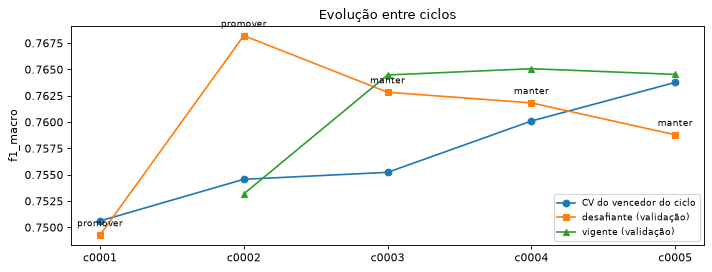

In [5]:
historico = promocao.ler_historico()
registro = ingestao.carregar_registro(cfg)
lotes = pd.DataFrame(registro["lotes"])
novos_por_ciclo = lotes[lotes["status"] == "incorporado"].groupby("incorporado_no_ciclo")["arquivo"].apply(lambda s: ", ".join(Path(a).stem for a in s))
comparacao = historico.set_index("cycle_id").join(novos_por_ciclo.rename("lotes_incorporados"))
mudancas = []
for cid in comparacao.index:
    vot = ler_json(Path("evidencias") / cid / "votacao_features.json") or {}
    mudancas.append({"cycle_id": cid, "n_features": len(vot.get("eleitas", [])),
                     "features_entraram": ",".join(vot.get("mudancas", {}).get("entraram", [])) if vot.get("mudancas", {}).get("ciclo_anterior") else "(primeiro ciclo)",
                     "features_sairam": ",".join(vot.get("mudancas", {}).get("sairam", []))})
comparacao = comparacao.join(pd.DataFrame(mudancas).set_index("cycle_id"))
cols = ["data_version", "gatilho", "lotes_incorporados", "n_features", "features_entraram", "features_sairam", "algoritmo_vencedor",
        "cv_vencedor", "metrica_desafiante_validacao", "metrica_vigente_validacao", "delta", "decisao", "versao_vigente_apos"]
display(comparacao[cols])
comparacao[cols].to_csv(EVID / "comparacao_ciclos.csv")

if len(historico) > 1:
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(historico["cycle_id"].str[:5], historico["cv_vencedor"], marker="o", label="CV do vencedor do ciclo")
    ax.plot(historico["cycle_id"].str[:5], historico["metrica_desafiante_validacao"], marker="s", label="desafiante (validação)")
    ax.plot(historico["cycle_id"].str[:5], historico["metrica_vigente_validacao"], marker="^", label="vigente (validação)")
    for i, d in enumerate(historico["decisao"]):
        ax.annotate(d, (i, historico["metrica_desafiante_validacao"].iloc[i]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
    ax.set_ylabel(cfg["avaliacao"]["metrica_principal"]); ax.set_title("Evolução entre ciclos"); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(EVID / "evolucao_ciclos.png"); plt.show()

## Registro no MLflow e encerramento do ciclo

In [6]:
salvar_json({"cycle_id": ctx["cycle_id"], "metricas_teste": m_teste, "verificacoes": verificacoes, "vigente": v["versao"]},
            EVID / "previsoes_verificacoes.json")
with rastreamento.run_etapa(ctx, cfg, "05_previsoes", "05_previsoes", tags={"versao_vigente": v["versao"]}) as run:
    mlflow.log_params({"versao_vigente": v["versao"], "algoritmo_vigente": v["algoritmo"], "run_id_vigente": v["run_id"], "n_teste": len(teste)})
    mlflow.log_metrics({f"teste_{k}": val for k, val in m_teste.items()})
    for nome_arq in ["previsoes_teste.csv.gz", "previsoes_verificacoes.json", "comparacao_ciclos.csv"]:
        mlflow.log_artifact(str(EVID / nome_arq))
    run_id = run.info.run_id

rastreamento.atualizar_run_pai(ctx, tags={"status_ciclo": "concluido"}, metricas={f"teste_{cfg['avaliacao']['metrica_principal']}_vigente": m_teste[cfg["avaliacao"]["metrica_principal"]]})
ctx = ciclo.registrar_etapa(ctx, "05_previsoes", run_id=run_id, metricas_teste=m_teste)
rastreamento.encerrar_run_pai(ctx, "FINISHED")
resumo = relatorio.salvar_resumo_ciclo(ctx)
display(Markdown(resumo))

🏃 View run c0005-20261123T211722Z/05_previsoes at: http://127.0.0.1:5000/#/experiments/1/runs/2dc956dc151147f7aed78c07b37091ff
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run ciclo-c0005-20261123T211722Z at: http://127.0.0.1:5000/#/experiments/1/runs/d9c0aa0272734360ab069dc0664dfec2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


## Ciclo `c0005-20261123T211722Z` — decisão: **MANTER**

| Campo | Valor |
|---|---|
| cycle_id | `c0005-20261123T211722Z` |
| data_version | `dv005-e930a6b0` |
| gatilho | `schedule` |
| execução | https://github.com/pedrosantos2/n3_cybersecurity/actions/runs/45267993081 |
| commit | `1fdb4996ae` |

### Dados
- Lotes novos incorporados: lote_0005 (4961 registros novos únicos)
- Base consolidada: 49701 registros; partições: {'treino': 34878, 'teste': 7484, 'validacao': 7339}

### Votação de features (3 métodos)
- 29 features eleitas: `kw_cms, url_length, path_length, num_path_tokens, num_letters, query_length, num_slash, path_depth, tld_com, has_exec_extension, has_ip, has_query, host_length, ratio_letters, ratio_digits, num_params, digits_in_host, ratio_special, num_digits, entropy, num_ampersand, num_equal, num_special, num_question, kw_malware, num_dots, ext_php, longest_token, tld_ip`
- vs. c0004-20261122T170836Z: entraram ['has_exec_extension']; saíram ['num_hyphen', 'num_suspicious_words']
- Estabilidade entre folds (Jaccard médio): 0.936

### Competição (validação cruzada, f1_macro)
| Papel | Algoritmo | Média | Desvio |
|---|---|---|---|
| modelo_a | random_forest | 0.7363 | 0.0034 |
| modelo_b | xgboost | 0.7638 | 0.0044 |

Vencedor do ciclo: **modelo_b (xgboost)** — maior média de f1_macro na validação cruzada (Δ=0.0274)

### Promoção controlada (holdout de validação)
- Desafiante: 0.7588 | Vigente: 0.7645 | Δ: -0.0057 | limiar: 0.002
- Decisão: **manter** — supera_vigente: Δ=-0.0057 (desafiante 0.7588 x vigente 0.7645); limiar 0.002

### Previsões com o vigente (teste reservado)
- Vigente: v0002 | f1_macro = 0.7676 | accuracy = 0.7692
- Teste integrado: todas as verificações OK

### Monitoramento de drift (critério 10)
- Nível: **estavel**
- PSI máximo 0.008 (`tld`)
